In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [75]:
df = pd.read_csv('/Users/anasghonaim/Library/CloudStorage/OneDrive-Personal/Ironhack/Labs/Week 5/amz_uk_price_prediction_dataset.csv')

In [76]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [77]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [78]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [79]:
# The top three categories with high prevelace of bestsellers are Grocery, Smart Home Security & Lighting, and Health & Personal Care.
# Add proportion calculation to the crosstab
prop_result = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
prop_result = prop_result.sort_values(by=True, ascending=False)
prop_result

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


In [80]:
from scipy.stats import chi2_contingency
_ , chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_p_value

# Ability to reject the null hypothesis. There is a significant association between category and isBestSeller.

np.float64(0.0)

In [81]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

# The cramer value of 0.122 suggests a weak association between category and isBestSeller.

0.1222829439760564

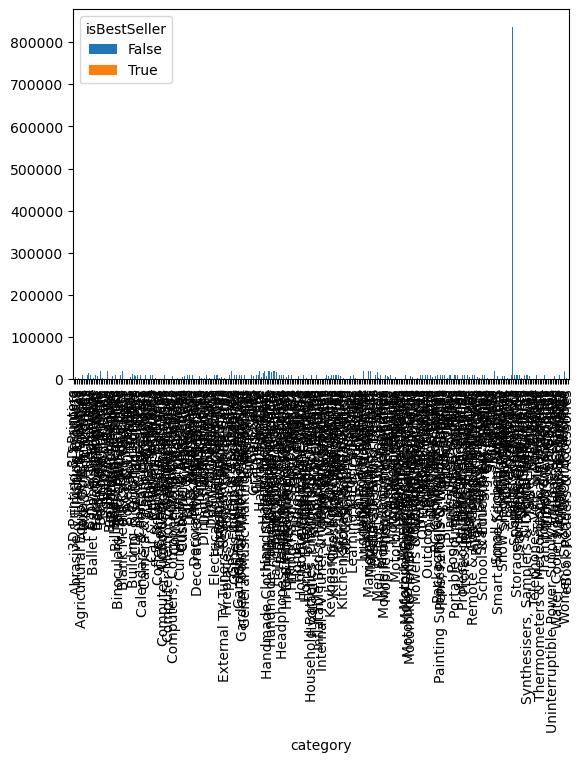

In [82]:
# Visualize relation between category and isBestSeller using a stacked bar chart
crosstab_result.plot(kind='bar', stacked=True)
plt.show()

In [83]:
def tukeys_test_outliers(df, column_name):
    data = df[column_name]
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Keep only rows within bounds
    return df[(data >= lower_bound) & (data <= upper_bound)]

In [84]:
df_cleaned = tukeys_test_outliers(df, 'price')

In [85]:
top_20_categories = df_cleaned['category'].value_counts().nlargest(20).index
df_top_20 = df_cleaned[df_cleaned['category'].isin(top_20_categories)]

/var/folders/wc/048rx86x7bqbzmjn7nr46j_80000gn/T/ipykernel_2092/4248453838.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")


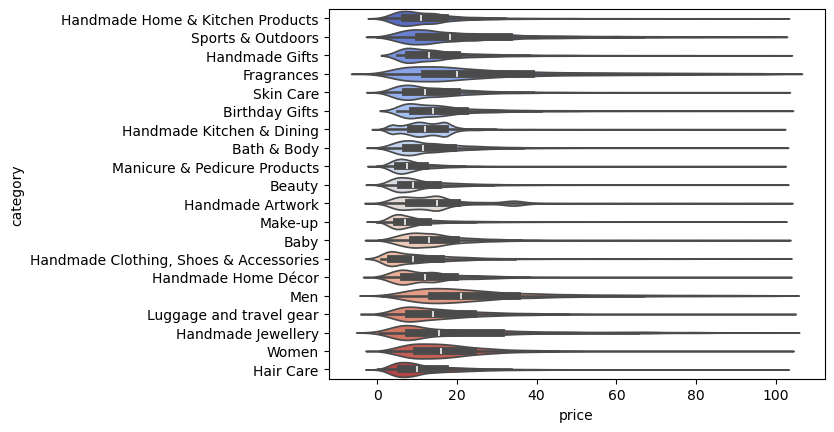

In [86]:

sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")
plt.show()

In [ ]:
df.groupby('category')['price'].median().sort_values(ascending=False)

# Laptops tend to have the highest median price among the categories analyzed, followed by Boxing Shoes.

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

<Axes: xlabel='price', ylabel='category'>

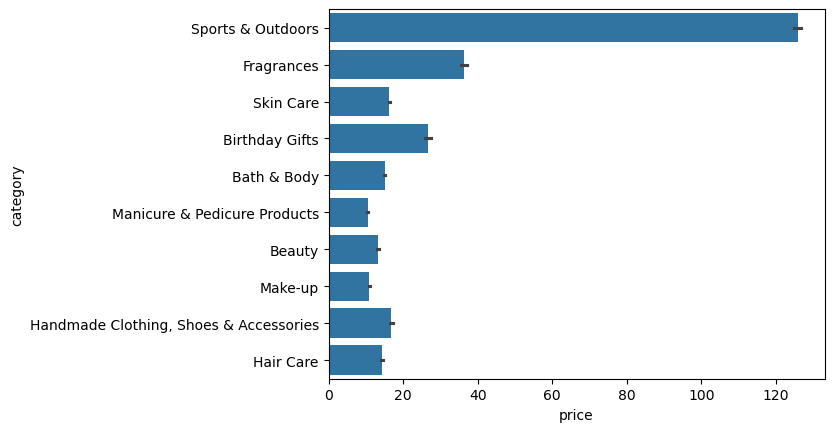

In [91]:
top_10_categories = df['category'].value_counts().nlargest(10).index
df_top_10 = df[df['category'].isin(top_10_categories)]
df_top_10.groupby('category')['price'].mean().sort_values(ascending=False)
sns.barplot(data=df_top_10, x='price', y='category')

In [92]:
# Laptops has the highest average price among the analyzed categories.
df.groupby('category')['price'].mean().sort_values(ascending=False)

category
Laptops                  1087.987827
3D Printers              1018.036129
Desktop PCs               926.816064
Home Office Furniture     622.135898
Test & Measurement        559.382973
                            ...     
Bedding Accessories         8.835220
Adapters                    8.750197
Signs & Plaques             8.275136
Arts & Crafts               8.182523
Office Paper Products       7.047684
Name: price, Length: 296, dtype: float64

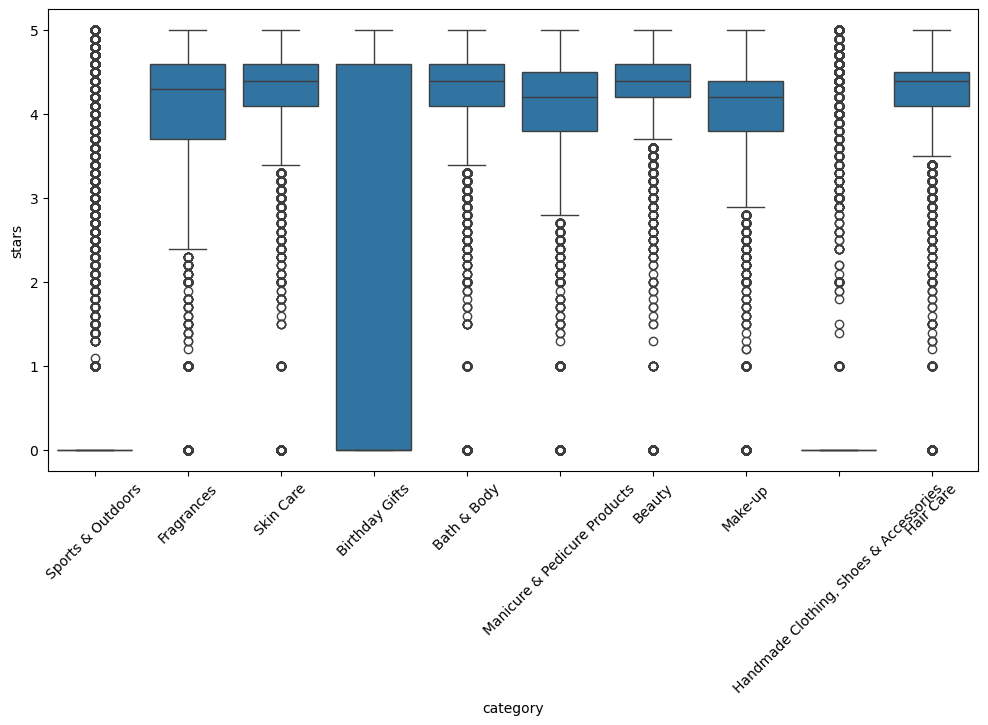

In [114]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top_10, x='category', y='stars')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Computer memory category tends to receive higher ratings compared to other categories.

df.groupby('category')['stars'].median().sort_values(ascending=False)


category
Computer Memory                4.7
Hobbies                        4.6
Beer, Wine & Spirits           4.6
Laptop Accessories             4.6
Kids' Play Figures             4.6
                              ... 
KVM Switches                   0.0
Karaoke Equipment              0.0
Lab & Scientific Products      0.0
Laptops                        0.0
eBook Readers & Accessories    0.0
Name: stars, Length: 296, dtype: float64

In [ ]:
# Judging by both correlation coefficients, there is a linear and negative correlation between ratings and price, however, it is a weak correlation and stastically insignificant.
correlation_pearson = df["stars"].corr(df["price"], method="pearson")
correlation_spearman = df["stars"].corr(df["price"], method="spearman")

correlation_pearson, correlation_spearman

(np.float64(-0.1249067326214854), np.float64(-0.13316425462433998))

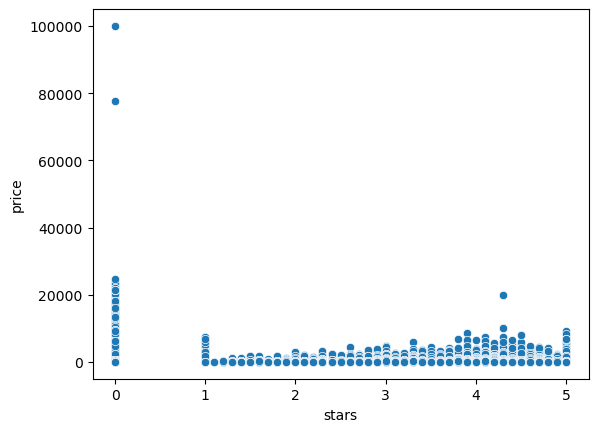

In [ ]:
# Products without ratings tend to have lower prices. Additionally, they are skeweing the correlation results.
# The correlation is insignificant when considering all products, but becomes weakly negative and significant when excluding unrated products.

sns.scatterplot(data=df, x='stars', y='price')
plt.show()

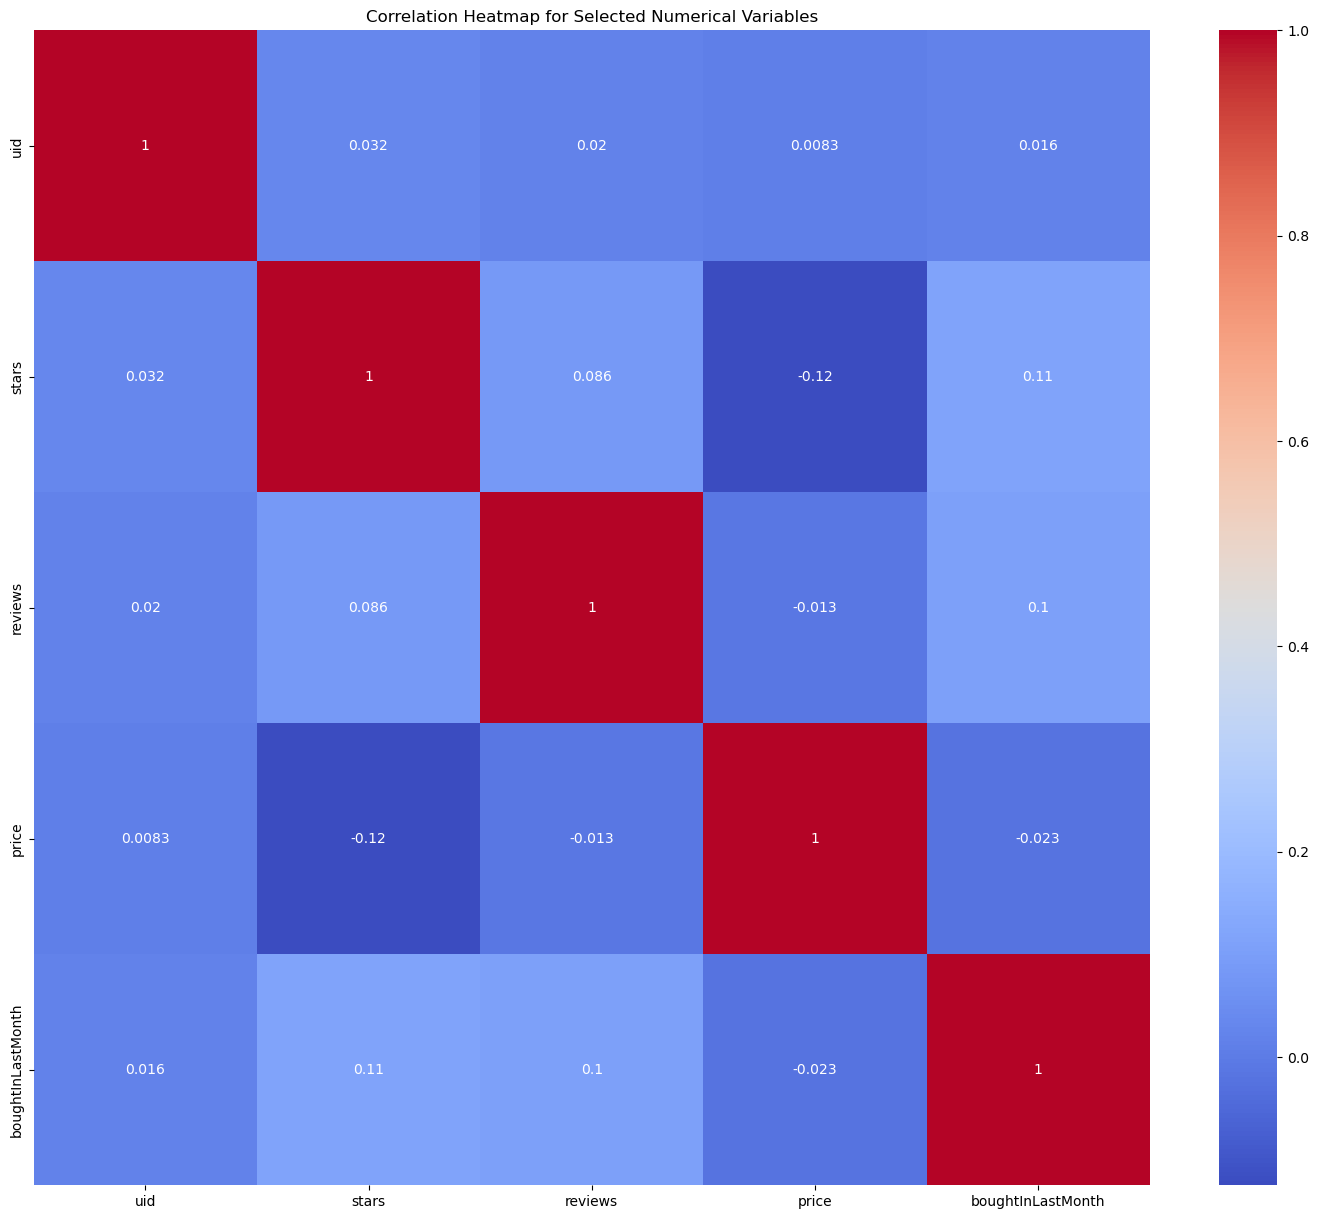

In [ ]:
# Numerical columns have no correlation with each other as shown by the heatmap.

potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

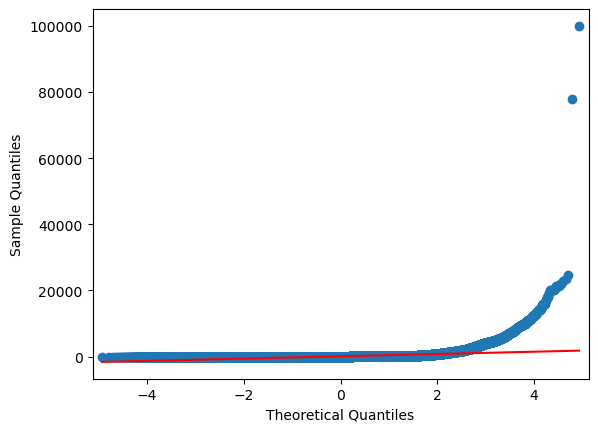

In [ ]:
# Product prices does not follow a normal distribution as shown by the Q-Q plot.

import statsmodels.api as sm

sm.qqplot(df['price'], line='s')
plt.show()